# 02 — Limpieza y features (Lending Club)

**Proyecto final de Machine Learning — Entrega final**

Toma el dataset ya explorado en `01_exploracion_inicial.ipynb` y aplica, de
forma reproducible y a través de `src/`, las decisiones de limpieza y
feature engineering acordadas:

- `fico_range_low` / `fico_range_high` (corr. 1.00) -> se combinan en `fico_avg`.
- `installment` (corr. 0.95 con `loan_amnt`) -> se descarta.
- Outliers de `annual_inc` y `dti` -> se winsorizan con topes calculados
  **solo con train** y reaplicados a validación.
- `emp_length` faltante -> categoría `"Desconocido"`, no imputación por moda.

Al final se deja el `ColumnTransformer` de preprocesamiento listo (sin
ajustar todavía) para usarse en `03_modelos.ipynb`.

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path.cwd().parent))
from src.data import load_dataset, RANDOM_SEED, TARGET
from src.features import build_features, build_preprocessor, LEAKAGE_COLUMNS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
np.random.seed(RANDOM_SEED)

FIG = Path("reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

## 1. Carga + target + split temporal (vía `src/data.py`)


In [3]:
import os
size_mb = os.path.getsize("/content/accepted_2007_to_2018Q4.csv") / (1024**2)
print(f"Tamaño del archivo: {size_mb:.1f} MB")

with open("/content/accepted_2007_to_2018Q4.csv") as f:
    n_lineas = sum(1 for _ in f)
print(f"Líneas totales (incluyendo header): {n_lineas:,}")

Tamaño del archivo: 1686.5 MB
Líneas totales (incluyendo header): 2,394,486


In [4]:
DATA_PATH = "/content/accepted_2007_to_2018Q4.csv"

# frac=1.0: dataset COMPLETO
train, valid = load_dataset(DATA_PATH, frac=0.5, seed=RANDOM_SEED)

print(f"Train: {train['issue_dt'].min():%Y-%m} a {train['issue_dt'].max():%Y-%m}  (n={len(train):,})")
print(f"Valid: {valid['issue_dt'].min():%Y-%m} a {valid['issue_dt'].max():%Y-%m}  (n={len(valid):,})")
print(f"Tasa de default  train={train[TARGET].mean():.3f}  valid={valid[TARGET].mean():.3f}")

Train: 2007-06 a 2016-09  (n=593,573)
Valid: 2016-10 a 2018-12  (n=149,951)
Tasa de default  train=0.199  valid=0.263


## 2. Control de leakage (documentación)

No se cargó ninguna columna posterior a la originación: `src/data.py` usa una
lista blanca (`COLUMNAS_UTILES`). La siguiente lista (`LEAKAGE_COLUMNS` en
`src/features.py`) deja constancia explícita de qué se excluyó y por qué,
aunque nunca llegó a este notebook.

In [3]:
print(f"Columnas de leakage documentadas y excluidas: {len(LEAKAGE_COLUMNS)}")
LEAKAGE_COLUMNS

Columnas de leakage documentadas y excluidas: 24


['total_pymnt',
 'total_pymnt_inv',
 'total_rec_prncp',
 'total_rec_int',
 'total_rec_late_fee',
 'out_prncp',
 'out_prncp_inv',
 'last_pymnt_d',
 'last_pymnt_amnt',
 'next_pymnt_d',
 'recoveries',
 'collection_recovery_fee',
 'last_fico_range_high',
 'last_fico_range_low',
 'last_credit_pull_d',
 'debt_settlement_flag',
 'settlement_status',
 'settlement_date',
 'settlement_amount',
 'hardship_flag',
 'hardship_type',
 'hardship_status',
 'funded_amnt',
 'funded_amnt_inv']

## 3. Features derivadas y outliers (vía `src/features.py`)

- `fit_thresholds=True` **solo** en train: calcula los topes de winsorización.
- Esos mismos topes (`thresholds`) se reaplican a validación — nunca se
  recalculan con datos de validación, para no filtrar información del futuro.

In [4]:
train_feat, thresholds = build_features(train, fit_thresholds=True)
valid_feat, _ = build_features(valid, thresholds=thresholds)

print("Topes de winsorización (calculados solo con train):")
thresholds

Topes de winsorización (calculados solo con train):


{'annual_inc_p99': np.float64(263493.7699999994), 'dti_cap': np.float64(38.37)}

In [ ]:
antes = train["annual_inc"].describe(percentiles=[.5, .99])[["50%", "99%", "max"]]
despues = train_feat["annual_inc"].describe(percentiles=[.5, .99])[["50%", "99%", "max"]]

comparacion = pd.DataFrame({"antes": antes, "despues": despues}).round(0)
comparacion

,antes,despues
50%,65000.0,65000.0
99%,250000.0,250000.0
max,9573072.0,250000.0


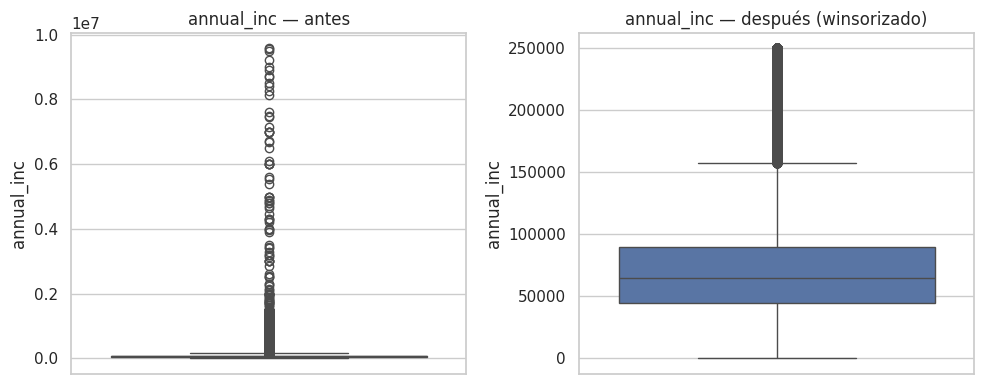

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=train["annual_inc"], ax=axes[0]); axes[0].set_title("annual_inc — antes")
sns.boxplot(y=train_feat["annual_inc"], ax=axes[1]); axes[1].set_title("annual_inc — después (winsorizado)")
fig.tight_layout()
fig.savefig(FIG/"11_annual_inc_antes_despues.png", dpi=120)
plt.show()

## 4. `emp_length`: categoría `"Desconocido"`

Se verifica que ya no queden faltantes y que la nueva categoría aparezca
con un volumen razonable (no es un caso raro aislado).

In [ ]:
print("Faltantes en emp_length (antes):", train["emp_length"].isna().sum())
print("Faltantes en emp_length (después):", train_feat["emp_length"].isna().sum())
print()
train_feat["emp_length"].value_counts(normalize=True).mul(100).round(2)

Faltantes en emp_length (antes): 59175
Faltantes en emp_length (después): 0



,proportion
emp_length,
10+ years,32.77
2 years,9.02
3 years,7.97
< 1 year,7.90
1 year,6.58
5 years,6.29
4 years,5.96
Desconocido,5.43
8 years,4.84


## 5. Variables redundantes eliminadas

Confirmamos que `fico_range_low`, `fico_range_high` e `installment` ya no
están, y que `fico_avg` y `credit_hist_months` sí se crearon.

In [ ]:
columnas_antes = set(train.columns)
columnas_despues = set(train_feat.columns)

print("Eliminadas:", sorted(columnas_antes - columnas_despues))
print("Nuevas:", sorted(columnas_despues - columnas_antes))

Eliminadas: ['fico_range_high', 'fico_range_low', 'installment']
Nuevas: ['credit_hist_months', 'fico_avg']


**Lectura:**
- `fico_range_low` y `fico_range_high` (corr. 1.00) se reemplazan por
  `fico_avg`, una sola señal de score crediticio.
- `installment` se descarta por su alta correlación con `loan_amnt` (0.95) y
  porque es casi una combinación lineal de `int_rate` y `term`, que ya están
  en el modelo.
- `credit_hist_months` queda como la antigüedad crediticia del solicitante en
  meses, derivada de `earliest_cr_line_dt` e `issue_dt`.

## 6. Preprocesador listo para modelado

Se arma (sin ajustar) el `ColumnTransformer` que se usará en `03_modelos.ipynb`. El `fit` se hará siempre sobre train, nunca sobre validación.

In [ ]:
from src.features import NUM_COLS_FINAL, CAT_COLS_FINAL

preprocess = build_preprocessor(NUM_COLS_FINAL, CAT_COLS_FINAL)

print("Numéricas:", NUM_COLS_FINAL)
print("Categóricas:", CAT_COLS_FINAL)
preprocess

Numéricas: ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'fico_avg', 'open_acc', 'revol_util', 'revol_bal', 'total_acc', 'credit_hist_months', 'delinq_2yrs', 'inq_last_6mths', 'pub_rec', 'pub_rec_bankruptcies']
Categóricas: ['term', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'purpose', 'verification_status', 'application_type', 'initial_list_status']


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(strategy='median')),
                                                 ('sc', StandardScaler())]),
                                 ['loan_amnt', 'int_rate', 'annual_inc', 'dti',
                                  'fico_avg', 'open_acc', 'revol_util',
                                  'revol_bal', 'total_acc',
                                  'credit_hist_months', 'delinq_2yrs',
                                  'inq_last_6mths', 'pub_rec',
                                  'pub_rec_bankruptcies']),
                                ('cat',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('oh',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['term', 'grade', 'sub_grade', 'emp_length',
                                  'home_ownership', 'purpose',
                                  'verification_status', 'application_type',
                                  'initial_list_status'])])

## 7. Guardar datasets procesados

Se guardan `train_feat` y `valid_feat` en `data/processed/`, junto con los
`thresholds`, para que `03_modelos.ipynb` no tenga que repetir este pipeline.

In [5]:
import json

OUT = Path("data/processed")
OUT.mkdir(parents=True, exist_ok=True)

train_feat.to_csv(OUT/"train.csv", index=False)
valid_feat.to_csv(OUT/"valid.csv", index=False)

with open(OUT/"thresholds.json", "w") as f:
    json.dump(thresholds, f, indent=2)

print("Guardado en", OUT.resolve())
print(f"train: {train_feat.shape}   valid: {valid_feat.shape}")

Guardado en /content/data/processed
train: (76408, 29)   valid: (39237, 29)
